<a href="https://colab.research.google.com/github/Rozieyati/Machine_Learning/blob/main/Assignment1_Apartment_Rent_Final_Submission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Predicting U.S. Apartment Rental Prices: Data Cleaning and a Comparison of Full, Stepwise, Ridge, LASSO and Principal Component Regression**

**Course:** STQD6024 Machine Learning | **Programme:** Master of Science (Data Science and Analytics) | **Semester:** 1, 2026/2027

**Group members:**

1. Rozieyati Azizahtul Asyikin Bte Rozaini (P166417)
2. Saranya A/P Ramis (P172415)
3. Intan Julianie Binti Mansor (P170177)

**Abstract.** This study predicts advertised monthly apartment rent in the United States using the *Apartment for Rent Classified* dataset (UCI ID 555). A systematic audit and cleaning process reduced 99,492 raw listings to 98,752 analysis-ready observations, resolving text-coded missing values, a default loading error that would have hidden 5,070 valid answers, duplicates, non-comparable listings, implausible values and two sources of target leakage. Five methods (full multiple linear regression, bidirectional stepwise regression by AIC, ridge, LASSO and principal component regression) were compared with nested 10-fold cross-validation. All five methods achieved highly comparable predictive performance (RMSE approximately 0.3441 on the log scale and adjusted R-squared approximately 0.367). The selection and tuning procedures generally favoured models with limited variable elimination, coefficient shrinkage or dimensionality reduction. Full multiple linear regression is therefore recommended as the simplest, fully interpretable model, while the moderate explanatory power shows that better location and property information, not stronger regularisation, is the key to improving rental price prediction.

# **1.0 Introduction**

Rent is the largest recurring expense for many households, and online adverts are now the main way rental units are marketed. Because each advert records size, rooms, location and conditions, listing data can estimate what a unit "should" rent for, helping tenants judge fairness, landlords set competitive rents and analysts identify price drivers.

Two challenges stand in the way. First, listing data are collected for advertising, not analysis: fields are optional, missing values are coded inconsistently, non-comparable listings are mixed in and the text often repeats the price, so a careless model can be biased or, through target leakage, look far more accurate than it is. Second, predictors are correlated (larger units have more bedrooms and bathrooms), so it is unclear whether ordinary least squares is adequate or whether variable selection (stepwise), shrinkage (ridge, LASSO) or dimension reduction (principal component regression, PCR) predicts better. This study addresses both with a reproducible workflow: a leakage-free dataset, then five methods compared under identical cross-validation.

**Research objectives (RO) and questions.** **RO1 (Section 3):** prepare a reliable, leakage-free dataset; which data-quality problems exist and how should each be treated? **RO2 (Section 4):** build and tune five models; how accurately do full MLR, stepwise, ridge, LASSO and PCR predict rent under cross-validation? **RO3 (Section 5):** compare variable selection, coefficient shrinkage and complexity across the methods. **RO4 (Section 6):** recommend the model that best balances accuracy, simplicity and interpretability, and state its limitations.

# **2.0 Dataset Description**

| Item | Description |
|---|---|
| Source | UCI Machine Learning Repository, dataset ID 555 (URL below) |
| File used | apartments_for_rent_classified_100K.csv (inside the official UCI archive) |
| Observations | 99,492 raw listings; 98,752 after cleaning |
| Response | `price`: advertised monthly rent (USD, continuous), modelled as log(price) |
| Numerical predictors (5 + 1 derived) | square_feet, bathrooms, bedrooms, latitude, longitude; number of amenities |
| Categorical predictors (5) | state (grouped into region), pets_allowed, has_photo, source, fee |
| Data type | Cross-sectional tabular data; the timestamp is not used (no time-series forecasting) |
| Limitations | 2019 asking rents, not agreed rents; over 90% of listings from one website; pet policy unstated in over half |

**Data access:** the notebook downloads the official archive from https://archive.ics.uci.edu/dataset/555/apartment+for+rent+classified and extracts the 100K file automatically (internet needed on the first run only).

# **3.0 Data Understanding and Preprocessing**

## **3.1 Environment and Data Access**

In [1]:
# Purpose: fix the random seed, record software versions, and obtain the dataset directly from the
#          official UCI archive (download and extract on the first run only), so any reader can reproduce it.
import os, sys, subprocess, importlib.util, zipfile, urllib.request, pathlib, warnings
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, seaborn as sns, sklearn
warnings.filterwarnings("ignore")                       # keep the PDF free of library warnings
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# 1. Locate the CSV locally; otherwise download the UCI ZIP and extract the 100K .7z archive
CSV_NAME = "apartments_for_rent_classified_100K.csv"
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/555/apartment+for+rent+classified.zip"
DATA_DIR = pathlib.Path("uci_apartment_data"); DATA_DIR.mkdir(exist_ok=True)
found = [p for p in [pathlib.Path(CSV_NAME)] if p.exists()] + list(DATA_DIR.rglob(CSV_NAME))
if not found:
    if importlib.util.find_spec("py7zr") is None:       # 7z extractor, installed only if absent
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "py7zr"])
    import py7zr
    zip_path = DATA_DIR / "uci_555.zip"
    if not zip_path.exists():
        req = urllib.request.Request(UCI_ZIP_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=180) as r, open(zip_path, "wb") as f:
            f.write(r.read())
    with zipfile.ZipFile(zip_path) as z:
        inner = [n for n in z.namelist() if "100K" in n and n.lower().endswith(".7z")]
        if not inner:
            raise FileNotFoundError(f"100K archive not found in UCI ZIP: {z.namelist()}")
        z.extract(inner[0], DATA_DIR)
    with py7zr.SevenZipFile(DATA_DIR / inner[0], mode="r") as arc:
        arc.extractall(DATA_DIR)
    found = list(DATA_DIR.rglob(CSV_NAME))
FILE = found[0]

# 2. Three loads: raw text (for auditing), pandas default, and corrected (only 'null' = missing)
raw = pd.read_csv(FILE, sep=";", encoding="cp1252", dtype=str, keep_default_na=False)
naive = pd.read_csv(FILE, sep=";", encoding="cp1252", low_memory=False)
df = pd.read_csv(FILE, sep=";", encoding="cp1252", low_memory=False, keep_default_na=False, na_values=["null"])

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"scikit-learn {sklearn.__version__} | seaborn {sns.__version__} | seed {SEED}")
print(f"Source: UCI dataset 555 | raw file: {raw.shape[0]:,} rows x {raw.shape[1]} columns")

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6
scikit-learn 1.6.1 | seaborn 0.13.2 | seed 42
Source: UCI dataset 555 | raw file: 99,492 rows x 22 columns


**Interpretation:** The data were obtained directly from the official UCI archive, so any reader can reproduce the analysis from the same source. The raw file contains 99,492 listings and 22 columns, slightly fewer than the "about 100,000" described by UCI, which is reported here for transparency. The file is semicolon-separated and Windows-encoded, so these settings are specified explicitly; a default comma-separated read would fail.

## **3.2 Data Quality Audit**

In [2]:
# Purpose: audit every data-quality problem before cleaning (missing values, loading errors, duplicates,
#          non-comparable listings, constants, extremes, leakage, high cardinality) in one compact table.
pct = lambda m: f"{m.sum():,} ({m.mean():.1%})"
audit = [
 ("Text 'null' = missing", "address", pct(raw.address == "null")),
 ("Text 'null' = missing", "pets_allowed", pct(raw.pets_allowed == "null")),
 ("Text 'null' = missing", "amenities", pct(raw.amenities == "null")),
 ("Missing key value", "price/rooms/location", pct(df[["price", "bathrooms", "bedrooms", "latitude", "state"]].isnull().any(axis=1))),
 ("'None' lost by default", "pets_allowed", f"{naive.pets_allowed.isnull().sum() - df.pets_allowed.isnull().sum():,}"),
 ("Exact duplicates", "all columns", f"{df.duplicated().sum():,}"),
 ("Not an apartment", "category", f"{(df.category != 'housing/rent/apartment').sum():,}"),
 ("Not a monthly price", "price_type", f"{(df.price_type != 'Monthly').sum():,}"),
 ("Constant column", "currency", f"{df.currency.nunique()} level"),
 ("Extreme maximum", "price", f"{df.price.max():,.0f} USD"),
 ("Extreme maximum", "square_feet", f"{df.square_feet.max():,} sq ft"),
 ("Leakage: $ amount in text", "body", pct(df.body.str.contains(r"\$"))),
 ("Leakage: exact rent in text", "body", pct(pd.Series([v == v and ((f"{int(v):,}" in b) or (f"${int(v)}" in b))
                                                         for v, b in zip(df.price, df.body.astype(str))]))),
 ("Leakage: copy of price", "price_display", "all rows"),
 ("High cardinality", "state / cityname", f"{df.state.nunique()} / {df.cityname.nunique():,}")]
print("=== Data Quality Audit ===")
print(pd.DataFrame(audit, columns=["Issue", "Column", "Count"]).to_string(index=False))

=== Data Quality Audit ===
                      Issue               Column          Count
      Text 'null' = missing              address 91,549 (92.0%)
      Text 'null' = missing         pets_allowed 55,354 (55.6%)
      Text 'null' = missing            amenities 16,044 (16.1%)
          Missing key value price/rooms/location     485 (0.5%)
     'None' lost by default         pets_allowed          5,070
           Exact duplicates          all columns             84
           Not an apartment             category             61
        Not a monthly price           price_type              4
            Constant column             currency        1 level
            Extreme maximum                price     52,500 USD
            Extreme maximum          square_feet   50,000 sq ft
  Leakage: $ amount in text                 body 48,798 (49.0%)
Leakage: exact rent in text                 body 17,763 (17.9%)
     Leakage: copy of price        price_display       all rows
           Hi

**Interpretation:** Auditing before analysis stops errors from propagating into the models (Rahm & Do, 2000). The problems fall into three groups. **(1) Missing data** is stored as the text `null`: it affects most addresses (92.0%) and over half of pet policies (55.6%), but only 485 rows (0.5%) lack the response, rooms or location (483 once duplicates and non-comparable listings are removed first). **(2) A hidden loading error:** pandas reads the text `None` as missing, but in `pets_allowed` it means *no pets allowed*; a default load would silently erase 5,070 valid answers. **(3) Comparability and leakage:** 84 duplicates and 65 non-apartment or non-monthly listings are not comparable; extremes such as 52,500 USD per month are implausible; and 49.0% of descriptions contain a dollar amount (17.9% the exact rent) while `price_display` copies the price, so both would leak the answer into the predictors (Kaufman et al., 2012).

## **3.3 Cleaning and Feature Engineering**

In [3]:
# Purpose: apply each cleaning rule in sequence with a row-count log (auditability), then build the
#          model-ready predictors and drop identifier, leakage, constant and free-text columns.
log = []
def log_step(name, before, after):
    log.append({"Step": name, "Rows before": before, "Rows after": after, "Removed": before - after})

# 1. Row-level cleaning
n = len(df); df = df.drop_duplicates();                                    log_step("Exact duplicates", n, len(df))
n = len(df); df = df[df.category == "housing/rent/apartment"];             log_step("Non-apartment listings", n, len(df))
n = len(df); df = df[df.price_type == "Monthly"];                          log_step("Non-monthly prices", n, len(df))
n = len(df); df = df.dropna(subset=["price", "bathrooms", "bedrooms", "latitude", "longitude", "state"])
log_step("Missing key values", n, len(df))
n = len(df); df = df[df.price.between(300, 10000) & df.square_feet.between(200, 5000)]
log_step("Implausible rent/size", n, len(df))

# 2. Feature engineering and recoding
df["n_amenities"] = df.amenities.fillna("").apply(lambda s: 0 if s == "" else len(s.split(",")))
df["pets_allowed"] = df.pets_allowed.fillna("Not specified").replace({"Cats,Dogs,None": "Not specified"})
df["source"] = np.where(df.source.isin(["RentDigs.com", "RentLingo"]), df.source, "Other")
regions = {"Northeast": "CT ME MA NH RI VT NJ NY PA", "Midwest": "IL IN MI OH WI IA KS MN MO NE ND SD",
           "South": "DE FL GA MD NC SC VA DC WV AL KY MS TN AR LA OK TX",
           "West": "AZ CO ID MT NV NM UT WY AK CA HI OR WA"}
df["region"] = df.state.map({s: r for r, ss in regions.items() for s in ss.split()})
df["log_price"], df["log_sqft"] = np.log(df.price), np.log(df.square_feet)

# 3. Final analysis variables
num_cols = ["log_sqft", "bathrooms", "bedrooms", "latitude", "longitude", "n_amenities"]
cat_cols = ["region", "pets_allowed", "has_photo", "source", "fee"]
target = "log_price"
clean = df[num_cols + cat_cols + [target, "price"]].copy()

print("=== Cleaning Log ===")
print(pd.DataFrame(log).to_string(index=False))
print(f"\nFinal: {len(clean):,} rows | {len(num_cols)} numerical + {len(cat_cols)} categorical | "
      f"missing: {int(clean.isnull().sum().sum())}")

# 4. Before vs After Cleaning — compact evidence table for Section 3.3
#    Only row-level cleaning is assessed here; CV preprocessing is performed later.
raw_count, final_count = len(raw), len(clean)
cleaning_comparison = pd.DataFrame({
    "Indicator": ["Observations", "Exact duplicates", "Non-apartment listings",
                  "Non-monthly listings", "Missing key values (price/rooms/location)",
                  "Rows failing price/size limits", "Observations retained (%)"],
    "Before cleaning": [raw_count, int(raw.duplicated().sum()),
                        int((raw.category != "housing/rent/apartment").sum()),
                        int((raw.price_type != "Monthly").sum()),
                        int(raw[["price", "bathrooms", "bedrooms", "latitude", "longitude", "state"]].eq("null").any(axis=1).sum()),
                        "See sequential log", "100.00%"],
    "After cleaning": [final_count, 0, 0, 0, 0, 0, f"{100*final_count/raw_count:.2f}%"]
})
print("\n=== Table: Before vs After Data Cleaning ===")
print(cleaning_comparison.to_string(index=False))

=== Cleaning Log ===
                  Step  Rows before  Rows after  Removed
      Exact duplicates        99492       99408       84
Non-apartment listings        99408       99347       61
    Non-monthly prices        99347       99343        4
    Missing key values        99343       98860      483
 Implausible rent/size        98860       98752      108

Final: 98,752 rows | 6 numerical + 5 categorical | missing: 0

=== Table: Before vs After Data Cleaning ===
                                Indicator    Before cleaning After cleaning
                             Observations              99492          98752
                         Exact duplicates                 84              0
                   Non-apartment listings                 61              0
                     Non-monthly listings                  4              0
Missing key values (price/rooms/location)                485              0
           Rows failing price/size limits See sequential log            

**Interpretation:** Cleaning removed 740 rows (0.74%), retaining 98,752 observations (99.26%) for analysis. Although the high retention rate preserves most of the original data, potential selection bias cannot be ruled out. The 483 rows missing the response, rooms or location were deleted rather than imputed because they represented a small proportion of the dataset. Nevertheless, the possibility of bias arising from systematic missingness cannot be excluded (Little & Rubin, 2019). Domain-based bounds (300 to 10,000 USD; 200 to 5,000 sq ft) removed 108 implausible listings that would distort a least-squares fit. Recoding reduced noise without losing information: states became four Census regions (finer location stays in the coordinates), rare sources became *Other*, an unstated pet policy became its own category, and amenities became a count. No missing values remain. The before-versus-after table confirms that every targeted problem (duplicates, non-apartment and non-monthly listings, missing key values) falls to zero while 99.26% of observations are retained; because the audit counts can overlap, the sequential log above is the correct source for the number of rows removed.

## **3.4 Exploratory Visualisation**

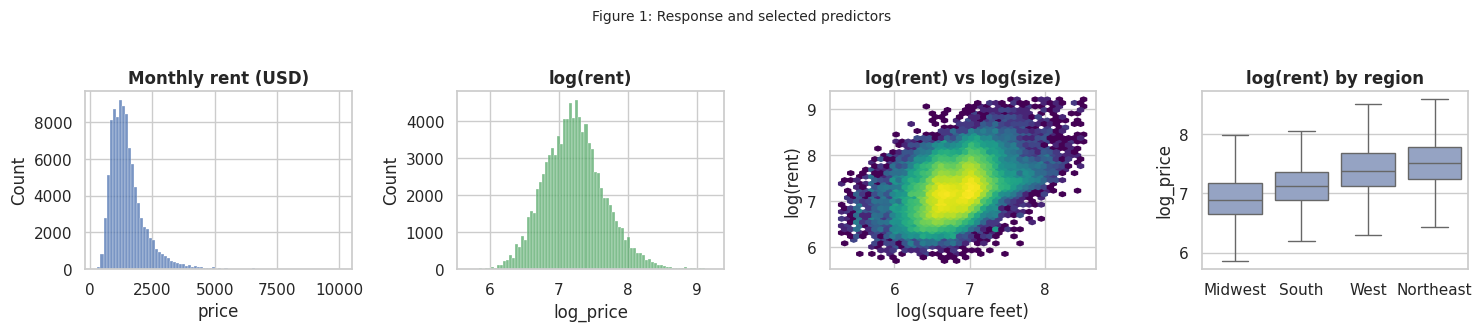

Skewness: price 2.49 -> log_price 0.33 | corr(log size, log rent) = 0.39
Median rent (USD): Midwest 975 | South 1,245 | West 1,595 | Northeast 1,850


In [4]:
# Purpose: visualise the response and selected numerical and categorical predictors (Figure 1).
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
sns.histplot(clean.price, bins=80, ax=ax[0], color="#4C72B0"); ax[0].set_title("Monthly rent (USD)", fontweight="bold")
sns.histplot(clean.log_price, bins=80, ax=ax[1], color="#55A868"); ax[1].set_title("log(rent)", fontweight="bold")
ax[2].hexbin(clean.log_sqft, clean.log_price, gridsize=40, cmap="viridis", mincnt=1, bins="log")
ax[2].set_xlabel("log(square feet)"); ax[2].set_ylabel("log(rent)"); ax[2].set_title("log(rent) vs log(size)", fontweight="bold")
reg_order = clean.groupby("region").log_price.median().sort_values().index
sns.boxplot(data=clean, x="region", y="log_price", order=reg_order, showfliers=False, ax=ax[3], color="#8DA0CB")
ax[3].set_title("log(rent) by region", fontweight="bold"); ax[3].set_xlabel("")
plt.suptitle("Figure 1: Response and selected predictors", fontsize=10, y=1.03); plt.tight_layout(); plt.show()

med = clean.groupby("region").price.median()
print(f"Skewness: price {clean.price.skew():.2f} -> log_price {clean.log_price.skew():.2f} | "
      f"corr(log size, log rent) = {clean[['log_sqft', 'log_price']].corr().iloc[0, 1]:.2f}")
print("Median rent (USD): " + " | ".join(f"{r} {med[r]:,.0f}" for r in reg_order))

**Interpretation:** Rent is strongly right-skewed (skewness 2.49): most units rent for 1,000 to 2,000 USD, with a long tail of expensive units. The log transformation makes it nearly symmetric (0.33), so the models are not dominated by a few expensive listings (Montgomery et al., 2021). Rent increases with size (r = 0.39 on the log scale), but the wide vertical spread shows that size alone explains only part of the price. Location has a large effect: median rent rises from 975 USD in the Midwest to 1,245 USD in the South, 1,595 USD in the West and 1,850 USD in the Northeast, almost double the Midwest.

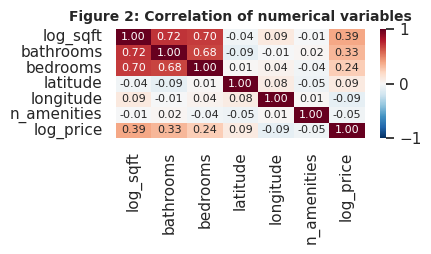

In [5]:
# Purpose: check linear association with the response and multicollinearity among the numerical predictors (Figure 2).
plt.figure(figsize=(4.6, 2.7))
sns.heatmap(clean[num_cols + [target]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Figure 2: Correlation of numerical variables", fontsize=10, fontweight="bold"); plt.tight_layout(); plt.show()

**Interpretation:** Size, bathrooms and bedrooms are strongly inter-correlated (r = 0.68 to 0.72), which is the classic setting in which least-squares coefficients become unstable and shrinkage methods may help (Hoerl & Kennard, 1970). Log size is the numerical variable most correlated with log rent (0.39). Latitude and longitude have weak linear correlations (|r| < 0.1), because location effects are not linear in coordinates; the region variable captures them more directly. These patterns motivate the comparison in Section 4: whether selection or shrinkage can handle the collinearity better than full MLR.

# **4.0 Regression Model Development**

**Design:** All five methods use the same **nested 10-fold cross-validation** (seed 42). In each outer training fold, stepwise selection is re-run on preprocessing fitted to that fold, and the tuning parameters of ridge, LASSO and PCR are chosen by **inner 5-fold CV in which standardisation and one-hot encoding (with meaningful reference levels) are re-fitted inside every inner training fold**, so neither selection nor tuning ever sees the validation data (Varma & Simon, 2006).

| Method | Selection / tuning procedure |
|---|---|
| Full MLR | All encoded columns, ordinary least squares (benchmark) |
| Bidirectional stepwise (AIC) | Start from the intercept-only model; at each step make the single addition **or** removal that lowers AIC (Akaike, 1974) most. **Stop** when no addition or removal lowers AIC |
| Ridge | Penalty chosen from 25 log-spaced values in [1e-4, 1e4] by minimum inner-CV MSE |
| LASSO | Penalty chosen from 25 log-spaced values in [1e-7, 1e-1] by minimum inner-CV MSE |
| PCR | Number of principal components chosen from **every** value 1 to p by minimum inner-CV MSE |

Metrics on each validation fold: RMSE and MAE (log scale and USD) and adjusted R-squared, $R^2_{adj} = 1-(1-R^2)\frac{n-1}{n-k-1}$, where $k$ is the number of non-zero coefficients (or components for PCR).

In [6]:
# Purpose: define reusable components so all five models are prepared, selected and scored identically:
#          leakage-safe preprocessing, AIC-based bidirectional stepwise selection, and the required metrics.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, lasso_path
from sklearn.model_selection import cross_val_score

# 1. Preprocessing with meaningful reference levels (Midwest, pet policy not stated, no photo, other source, no fee)
REFERENCE = ["Midwest", "Not specified", "No", "Other", "No"]
def make_preprocess():
    return ColumnTransformer([("num", StandardScaler(), num_cols),
                              ("cat", OneHotEncoder(drop=REFERENCE, handle_unknown="ignore", sparse_output=False), cat_cols)])

# 2. Bidirectional stepwise by AIC (intercept always included; Gram matrix cached for speed)
def stepwise_aic(Xm, y, tol=1e-6):
    n, p = Xm.shape
    D = np.column_stack([np.ones(n), Xm]); G, c, yy = D.T @ D, D.T @ y, y @ y
    def aic(cols):
        idx = [0] + [j + 1 for j in cols]
        beta = np.linalg.solve(G[np.ix_(idx, idx)], c[idx])
        sse = yy - beta @ c[idx]
        return n * np.log(sse / n) + 2 * len(idx)
    selected, current = [], aic([])
    while True:
        moves = [(aic(selected + [j]), "add", j) for j in range(p) if j not in selected]
        moves += [(aic([v for v in selected if v != j]), "remove", j) for j in selected]
        best_aic, action, j = min(moves)
        if best_aic >= current - tol:                    # stopping rule: no move lowers AIC
            return sorted(selected)
        selected = selected + [j] if action == "add" else [v for v in selected if v != j]
        current = best_aic

# 3. Required metrics: RMSE, MAE, adjusted R-squared (log scale) and RMSE/MAE in USD
def metrics(y_true, y_pred, k):
    n = len(y_true); r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    return {"RMSE": np.sqrt(np.mean((y_true - y_pred) ** 2)), "MAE": np.mean(np.abs(y_true - y_pred)),
            "AdjR2": 1 - (1 - r2) * (n - 1) / (n - k - 1),
            "RMSE_USD": np.sqrt(np.mean((np.exp(y_true) - np.exp(y_pred)) ** 2)),
            "MAE_USD": np.mean(np.abs(np.exp(y_true) - np.exp(y_pred))), "k": k}

OUTER_CV, INNER_CV = KFold(10, shuffle=True, random_state=SEED), KFold(5, shuffle=True, random_state=SEED)
RIDGE_ALPHAS, LASSO_ALPHAS = np.logspace(-4, 4, 25), np.logspace(-7, -1, 25)
X, y = clean[num_cols + cat_cols], clean[target].values
p = make_preprocess().fit(X).transform(X).shape[1]
print(f"Design matrix: {len(X):,} rows | {X.shape[1]} predictors -> {p} encoded columns | 10x5 nested CV")

Design matrix: 98,752 rows | 11 predictors -> 18 encoded columns | 10x5 nested CV


**Interpretation:** The 11 predictors expand to 18 encoded columns. Every reference level is chosen to be meaningful (Midwest, pet policy not stated, no photo, other source, no fee), so each coefficient answers a clear question, for example "how much more expensive is the West than the Midwest?". Because preprocessing, selection and tuning are all re-fitted inside each training fold, the validation folds remain unseen and the reported errors are honest out-of-sample estimates.

In [7]:
# Purpose: true nested CV, computed efficiently. In each outer fold, preprocessing is fitted on the outer
#          training data for Full MLR and stepwise. Ridge, LASSO and PCR are tuned by inner 5-fold CV in which
#          the scaler and encoder are re-fitted on EVERY inner training fold, so validation data are never seen.
#          (Equivalent to GridSearchCV with the preprocessing inside the pipeline, but each inner fold is
#          preprocessed once and all candidate values are scored on it, which is many times faster.)
def inner_tune(X_train, y_train):
    mse_r, mse_l, mse_p = [], [], []
    for itr, iva in INNER_CV.split(X_train):
        prep_i = make_preprocess().fit(X_train.iloc[itr])                 # 1. preprocessing on inner training fold
        A, B, ya, yb = prep_i.transform(X_train.iloc[itr]), prep_i.transform(X_train.iloc[iva]), y_train[itr], y_train[iva]
        mse_r.append([np.mean((yb - Ridge(alpha=a).fit(A, ya).predict(B)) ** 2) for a in RIDGE_ALPHAS])
        mse_l.append([np.mean((yb - Lasso(alpha=a, max_iter=10000, precompute=True).fit(A, ya).predict(B)) ** 2)
                      for a in LASSO_ALPHAS])
        pca = PCA(svd_solver="full").fit(A); SA, SB = pca.transform(A), pca.transform(B)
        mse_p.append([np.mean((yb - LinearRegression().fit(SA[:, :k], ya).predict(SB[:, :k])) ** 2)
                      for k in range(1, A.shape[1] + 1)])
    # 2. choose the value with the lowest mean inner-CV MSE
    return (RIDGE_ALPHAS[np.argmin(np.mean(mse_r, 0))], LASSO_ALPHAS[np.argmin(np.mean(mse_l, 0))],
            int(np.argmin(np.mean(mse_p, 0)) + 1))

records, tuning = [], []
for fold, (tr, va) in enumerate(OUTER_CV.split(X), start=1):
    X_train, X_valid, ytr, yva = X.iloc[tr], X.iloc[va], y[tr], y[va]
    prep = make_preprocess().fit(X_train)                                  # 3. outer-fold preprocessing
    Xtr, Xva = prep.transform(X_train), prep.transform(X_valid)
    selected = stepwise_aic(Xtr, ytr)
    ridge_alpha, lasso_alpha, pcr_k = inner_tune(X_train, ytr)             # 4. inner-CV tuning
    lasso_m = Lasso(alpha=lasso_alpha, max_iter=10000, precompute=True).fit(Xtr, ytr)
    pcr_m = Pipeline([("pca", PCA(n_components=pcr_k, svd_solver="full")), ("ols", LinearRegression())]).fit(Xtr, ytr)
    preds = {"Full MLR": (LinearRegression().fit(Xtr, ytr).predict(Xva), Xtr.shape[1]),
             "Stepwise": (LinearRegression().fit(Xtr[:, selected], ytr).predict(Xva[:, selected]), len(selected)),
             "Ridge": (Ridge(alpha=ridge_alpha).fit(Xtr, ytr).predict(Xva), Xtr.shape[1]),
             "LASSO": (lasso_m.predict(Xva), int(np.count_nonzero(lasso_m.coef_))),
             "PCR": (pcr_m.predict(Xva), pcr_k)}
    for name, (pred, k) in preds.items():                                  # 5. score on the unseen outer fold
        records.append({"Model": name, "Fold": fold, **metrics(yva, pred, k)})
    tuning.append([len(selected), ridge_alpha, lasso_alpha, int(np.count_nonzero(lasso_m.coef_)), pcr_k])

cv = pd.DataFrame(records)
tun = np.asarray(tuning)
print("=== Inner-CV Tuning across Outer Folds (min–max) ===")
print(f"Stepwise columns: {tun[:,0].min():.0f}–{tun[:,0].max():.0f} / {p}")
print(f"Ridge alpha: {tun[:,1].min():.3g}–{tun[:,1].max():.3g}")
print(f"LASSO alpha: {tun[:,2].min():.3g}–{tun[:,2].max():.3g}; "
      f"non-zero: {tun[:,3].min():.0f}–{tun[:,3].max():.0f}")
print(f"PCR components: {tun[:,4].min():.0f}–{tun[:,4].max():.0f} / {p}")

=== Inner-CV Tuning across Outer Folds (min–max) ===
Stepwise columns: 16–18 / 18
Ridge alpha: 1–10
LASSO alpha: 1e-07–3.16e-05; non-zero: 18–18
PCR components: 17–18 / 18


**Interpretation:** Every tuning procedure moved towards the full model. Stepwise kept 16 to 18 of the 18 columns, so AIC found almost every column useful. The tuned ridge penalty (1 to 10) is negligible relative to about 89,000 training rows. The tuned LASSO penalty reached the lowest grid value ($10^{-7}$) in several folds and never exceeded $3.2 	imes 10^{-5}$, keeping all 18 coefficients in every fold; within the tested range the smallest penalties are preferred, so the best LASSO model is practically the least-squares fit. PCR kept 17 to 18 of 18 components, so it reduced almost no dimensions. In short, the data favour no selection, no shrinkage and no dimension reduction.

In [8]:
# Purpose: summarise the cross-validated performance of the five models (Table 1).
order = ["Full MLR", "Stepwise", "Ridge", "LASSO", "PCR"]
g = cv.groupby("Model").agg(["mean", "std"]).loc[order]
tbl = pd.DataFrame({"RMSE": g[("RMSE", "mean")], "SD": g[("RMSE", "std")], "MAE": g[("MAE", "mean")],
                    "Adj R2": g[("AdjR2", "mean")], "RMSE $": g[("RMSE_USD", "mean")],
                    "MAE $": g[("MAE_USD", "mean")], "k": g[("k", "mean")]}).round(
                    {"RMSE": 4, "SD": 4, "MAE": 4, "Adj R2": 4, "RMSE $": 1, "MAE $": 1, "k": 1})
print("=== Table 1: 10-Fold CV Performance (means; SD of RMSE; $ = USD) ===")
print(tbl.to_string())

=== Table 1: 10-Fold CV Performance (means; SD of RMSE; $ = USD) ===
            RMSE      SD     MAE  Adj R2  RMSE $  MAE $     k
Model                                                        
Full MLR  0.3441  0.0042  0.2698  0.3667   629.0  414.5  18.0
Stepwise  0.3441  0.0042  0.2698  0.3667   629.1  414.5  17.2
Ridge     0.3441  0.0042  0.2698  0.3667   629.0  414.5  18.0
LASSO     0.3441  0.0042  0.2698  0.3667   629.0  414.5  18.0
PCR       0.3441  0.0042  0.2698  0.3667   629.0  414.5  17.7


**Interpretation:** All five models are equally accurate: RMSE 0.3441, MAE 0.2698 and adjusted R-squared 0.3667, identical to four decimal places. In practical terms, a typical prediction is off by about 415 USD (MAE), around 31% of the actual rent on the multiplicative scale, and the models explain about 37% of the variation in log rent. The fold-to-fold SD of RMSE (0.0042) is substantially larger than the observed differences between methods, suggesting that no practically meaningful improvement in predictive performance was demonstrated at the reported precision. This answers RQ2: under rigorous cross-validation, selection, shrinkage and dimension reduction bring no accuracy gain over full MLR for this dataset.

# **5.0 Model Investigation and Critical Analysis**

## **5.1 Selected Variables, Coefficient Shrinkage and Complexity**

In [9]:
# Purpose: refit the five methods on the full data to compare which variables each keeps (selection),
#          how strongly coefficients are reduced (shrinkage) and how many terms each uses (complexity) (Table 2).
prep_f = make_preprocess().fit(X); Xf = prep_f.transform(X)
short = {"pets_allowed_": "pets_", "has_photo_": "photo_", "source_": "src_", ".com": ""}
names = [f.split("__")[1] for f in prep_f.get_feature_names_out()]
for a_, b_ in short.items():
    names = [nm.replace(a_, b_) for nm in names]

# 1. Re-use the tuning results from the nested CV (median over the 10 outer folds) instead of re-tuning:
#    this is much faster and keeps the final models consistent with the evaluated ones
RIDGE_ALPHA, LASSO_ALPHA = float(np.median(tun[:, 1])), float(np.median(tun[:, 2]))
PCR_K = int(np.round(np.median(tun[:, 4])))
mlr_f = LinearRegression().fit(Xf, y)
sel_f = stepwise_aic(Xf, y); step_c = np.zeros(Xf.shape[1]); step_c[sel_f] = LinearRegression().fit(Xf[:, sel_f], y).coef_
ridge_f = Ridge(alpha=RIDGE_ALPHA).fit(Xf, y)
lasso_f = Lasso(alpha=LASSO_ALPHA, max_iter=10000, precompute=True).fit(Xf, y)
pcr_f = Pipeline([("pca", PCA(n_components=PCR_K, svd_solver="full")), ("ols", LinearRegression())]).fit(Xf, y)
pcr_coef = pcr_f.named_steps["pca"].components_.T @ pcr_f.named_steps["ols"].coef_   # back to original columns

coef = pd.DataFrame({"MLR": mlr_f.coef_, "Step": step_c, "Ridge": ridge_f.coef_,
                     "LASSO": lasso_f.coef_, "PCR": pcr_coef}, index=names)
# Shrinkage % = reduction in absolute size relative to MLR (100 = removed, 0 = unchanged, negative = enlarged)
for m in ["Ridge", "LASSO"]:
    coef[f"{m} %"] = 100 * (coef.MLR.abs() - coef[m].abs()) / coef.MLR.abs()
print("=== Table 2: Standardised Coefficients and Shrinkage vs MLR ===")
print(coef.round({"MLR": 3, "Step": 3, "Ridge": 3, "LASSO": 3, "PCR": 3, "Ridge %": 1, "LASSO %": 1}).to_string())

nz = (coef[["MLR", "Step", "Ridge", "LASSO"]] != 0).sum()
l1 = coef[["MLR", "Step", "Ridge", "LASSO", "PCR"]].abs().sum()
print("\nNon-zero coefficients: " + " | ".join(f"{m} {nz[m]}" for m in nz.index) + f" | PCR k {pcr_f.named_steps['pca'].n_components_}")
print("Sum |coef|: " + " | ".join(f"{m} {l1[m]:.3f}" for m in l1.index))
print(f"Tuned (fold median): ridge {RIDGE_ALPHA:.3g} | LASSO {LASSO_ALPHA:.2e} | PCR k {PCR_K}")

=== Table 2: Standardised Coefficients and Shrinkage vs MLR ===
                    MLR   Step  Ridge  LASSO    PCR  Ridge %  LASSO %
log_sqft          0.163  0.163  0.163  0.163  0.163      0.0      0.0
bathrooms         0.065  0.065  0.065  0.065  0.065     -0.0      0.0
bedrooms         -0.048 -0.048 -0.048 -0.048 -0.048      0.0      0.0
latitude          0.006  0.006  0.006  0.006  0.006      0.6      0.1
longitude         0.054  0.054  0.054  0.054  0.054      0.2      0.0
n_amenities      -0.012 -0.012 -0.012 -0.012 -0.012      0.0     -0.0
region_Northeast  0.529  0.529  0.528  0.529  0.529      0.1      0.0
region_South      0.176  0.176  0.175  0.176  0.176      0.3      0.0
region_West       0.581  0.581  0.581  0.581  0.581      0.1      0.0
pets_Cats        -0.015 -0.015 -0.015 -0.015 -0.015      0.0      0.3
pets_Cats,Dogs   -0.017 -0.017 -0.017 -0.017 -0.017      0.3      0.1
pets_Dogs        -0.046 -0.046 -0.044 -0.045 -0.046      4.3      1.2
pets_None        -0.063 -0

**Interpretation:**

**Selection:-** On the full data, stepwise (AIC) and LASSO keep all 18 columns and PCR all 18 components: no method finds a column worth dropping, although this does not mean every predictor is individually important.

**Effects** (other variables fixed):- rents in the West and Northeast are about 79% and 70% higher than in the Midwest, and about 19% higher in the South; listings with a fee are about 19% higher; RentLingo and RentDigs listings are about 22% and 8% higher than other sources; and listings that forbid pets are about 6% cheaper than those with no stated policy. Bedrooms is negative once size is fixed (more bedrooms in the same area means smaller rooms), a sign of the collinearity in Figure 2.

**Shrinkage:-** Ridge reduces total coefficient size by only 0.6% (2.284 to 2.271), mostly on the rarest categories, dogs-only (126 rows, -4.3%) and fee (196 rows, -3.1%), because estimates based on little information are pulled most towards zero. LASSO, tuned to an almost zero penalty, shrinks essentially nothing.

## **5.2 Shrinkage Paths and the Cost of Sparsity**

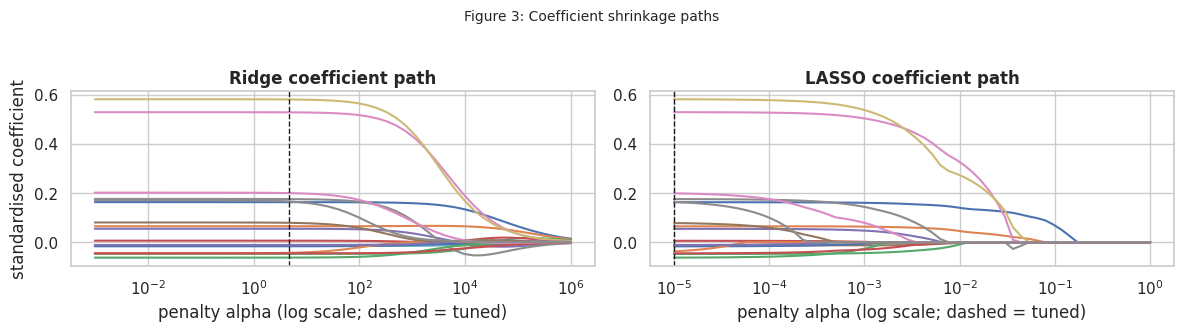

=== Table 3: Simpler Models versus 10-Fold CV RMSE (log scale) ===
LASSO alpha 1e-03: 13 non-zero coefficients, CV RMSE 0.3446
LASSO alpha 1e-02:  6 non-zero coefficients, CV RMSE 0.3544
LASSO alpha 3e-02:  4 non-zero coefficients, CV RMSE 0.3768
PCR with  3 components:          CV RMSE 0.3960
PCR with  6 components:          CV RMSE 0.3874
PCR with 10 components:          CV RMSE 0.3690
PCR with 14 components:          CV RMSE 0.3446


In [10]:
# Purpose: show how ridge and LASSO coefficients shrink as the penalty grows (Figure 3), and quantify the
#          accuracy cost of forcing a sparser LASSO model or fewer PCR components (Table 3).
ridge_grid = np.logspace(-3, 6, 50)
ridge_path = np.array([Ridge(alpha=a_).fit(Xf, y).coef_ for a_ in ridge_grid])
Xc, yc = Xf - Xf.mean(axis=0), y - y.mean()                        # centred: lasso_path has no intercept
la, lc, _ = lasso_path(Xc, yc, alphas=np.logspace(-5, 0, 60))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].plot(ridge_grid, ridge_path); ax[0].axvline(RIDGE_ALPHA, color="k", ls="--", lw=1)
ax[1].plot(la, lc.T); ax[1].axvline(max(LASSO_ALPHA, 1e-5), color="k", ls="--", lw=1)
for a_, t in zip(ax, ["Ridge", "LASSO"]):
    a_.set_xscale("log"); a_.set_xlabel("penalty alpha (log scale; dashed = tuned)"); a_.set_title(f"{t} coefficient path", fontweight="bold")
ax[0].set_ylabel("standardised coefficient")
plt.suptitle("Figure 3: Coefficient shrinkage paths", fontsize=10, y=1.03); plt.tight_layout(); plt.show()

print("=== Table 3: Simpler Models versus 10-Fold CV RMSE (log scale) ===")
# 10-fold CV RMSE of a few deliberately simpler models (larger LASSO penalties, fewer PCR components)
cv_rmse = lambda model: np.sqrt(-cross_val_score(model, X, y, cv=OUTER_CV, scoring="neg_mean_squared_error").mean())
for a_ in [1e-3, 1e-2, 3e-2]:
    m_ = Lasso(alpha=a_, max_iter=10000)
    print(f"LASSO alpha {a_:.0e}: {int(np.sum(m_.fit(Xf, y).coef_ != 0)):>2} non-zero coefficients, CV RMSE {cv_rmse(Pipeline([("prep", make_preprocess()), ("model", Lasso(alpha=a_, max_iter=10000))])):.4f}")
for k in [3, 6, 10, 14]:
    print(f"PCR with {k:>2} components:          CV RMSE {cv_rmse(Pipeline([('prep', make_preprocess()), ('pca', PCA(n_components=k)), ('ols', LinearRegression())])):.4f}")

**Interpretation:** Ridge coefficients stay flat until the penalty reaches about $10^2$ and then shrink smoothly; LASSO coefficients drop to exactly zero one by one, with log size the last to survive (Tibshirani, 1996). The tuned penalties lie in the flat region, which is why the penalised models match full MLR. Table 3 prices simplicity: a 13-coefficient LASSO costs only +0.15% RMSE (0.3446), but 6 coefficients cost +3.0% (0.3544). PCR degrades faster: 10 components cost +7.2% (0.3690) and 3 components +15.1% (0.3960), because components are chosen to explain the predictors, not rent, so low-variance directions such as the region dummies can still carry most of the price information (Jolliffe, 1982).

**Critical assessment:** Selection and shrinkage trade a small bias for lower variance, which pays off when data are scarce or collinearity is severe (James et al., 2021). With about 5,000 observations per coefficient and a maximum predictor correlation of 0.72, least-squares variance is already tiny, so there is nothing to gain. The remaining prediction error may partly reflect model specification limitations and omitted variables rather than excessive model variance. With an adjusted R-squared of approximately 0.37, additional information on city, neighbourhood and building condition may improve predictive performance beyond what regularisation or variable selection alone can achieve.

# **6.0 Conclusions and Recommendations**

| Criterion (10-fold CV) | **Full MLR** | Stepwise (AIC) | Ridge | LASSO | PCR |
|---|---|---|---|---|---|
| RMSE log scale (USD) | 0.3441 (629.0) | 0.3441 (629.1) | 0.3441 (629.0) | 0.3441 (629.0) | 0.3441 (629.0) |
| MAE (USD) | 414.5 | 414.5 | 414.5 | 414.5 | 414.5 |
| Adjusted R-squared | 0.3667 | 0.3667 | 0.3667 | 0.3667 | 0.3667 |
| Terms used (mean) | 18 | 17.2 | 18 | 18 | 17.7 components |
| Tuning required | **None** | Selection search | Penalty | Penalty | Components |

**Recommended model: Full multiple linear regression.** The evidence supports this choice on four grounds:-

(1) **Comparable  accuracy:** all five methods achieve nearly identical RMSE, MAE and adjusted R-squared at the reported precision, with differences substantially smaller than the observed fold-to-fold variation.

(2) **The alternatives converge to it:** AIC stepwise and LASSO keep all 18 columns on the full data, the tuned ridge penalty is negligible, and PCR keeps all components, so no method finds a simpler model that predicts as well (which does not mean every predictor is individually important).

(3) **Simplicity and transparency:** full MLR needs no search or tuning, and its coefficients have a direct percentage interpretation (for example, West about 79% above Midwest).

(4) **Stability:** its estimates do not depend on a tuned penalty or on which columns a search happens to select in a given sample.

**Practical recommendations:** Treat a prediction as a *typical* rent with an expected error of about 415 USD: the model suits flagging adverts far above or below the market, not exact price setting. Region and size are the main drivers to check first. If a smaller model is required, a 13-coefficient LASSO is the best compromise (+0.15% RMSE); PCR is not recommended.

**Limitations:** (1) *Data:* 2019 asking (not agreed) rents, dominated by one website, with pet policy often unstated. (2) *Predictors:* coarse location and excluded text limit adjusted R-squared to about 0.37. (3) *Methods:* with about 99,000 rows almost every variable improves AIC, so stepwise is a weak filter and post-selection inference is optimistic (Harrell, 2015); adjusted R-squared for penalised models approximates degrees of freedom by non-zero terms; log back-transformation slightly underestimates mean rents. (4) *Form:* all models are linear and additive.

**Future work:** Gains will come from richer information, not different penalties: city or ZIP-level location, size-by-region interactions, building characteristics and non-linear models (e.g. gradient boosting) under the same nested cross-validation.

# **References**

Akaike, H. (1974). A new look at the statistical model identification. *IEEE Transactions on Automatic Control, 19*(6), 716–723.

Harrell, F. E. (2015). *Regression Modeling Strategies* (2nd ed.). Springer.

Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. *Technometrics, 12*(1), 55–67.

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.

Jolliffe, I. T. (1982). A note on the use of principal components in regression. *Applied Statistics, 31*(3), 300–303.

Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining. *ACM TKDD, 6*(4), 1–21.

Little, R. J. A., & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3rd ed.). Wiley.

Montgomery, D. C., Peck, E. A., & Vining, G. G. (2021). *Introduction to Linear Regression Analysis* (6th ed.). Wiley.

Rahm, E., & Do, H. H. (2000). Data cleaning: Problems and current approaches. *IEEE Data Eng. Bull., 23*(4), 3–13.

Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *JRSS-B, 58*(1), 267–288.

UCI Machine Learning Repository. (2019). *Apartment for Rent Classified* (ID 555).

Varma, S., & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics, 7*, 91.